In [1]:
import numpy as np
import polars as pl
import typol as tp
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, Pool

from Answer import Answer, AnswerQ11NullsAsOnes, PredictedAndActualQ11, AnswerParts1_6_NoQ1, PredictedAndActualQ1, AnswerParts1_6, AnswerParts1_2_3_4_5_6_NotQ11, OnlyQ11

In [94]:
labels = {
    0: "None",
    1: "1...2",
    2: "3...4",
    3: "5...6",
    4: "6...10",
    5: "10...20",
    6: ">20",
}

In [102]:
def predict_habits(data: tp.DataFrame[Answer]) -> tp.DataFrame[PredictedAndActualQ11]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    data = data.filter(data.s.Q1 > 1)
    data = data.with_columns(data.s.Q11_1.fill_null(66)).filter(data.s.Q11_1 != 66)
    training_data = data.transform(AnswerParts1_2_3_4_5_6_NotQ11)
    X_train, X_test, y_train, y_test = train_test_split(
        training_data.dataframe,
        data[Answer.Q11_1].to_list(),
        test_size=0.30,
        random_state=0
    )
    books_read_predictor = RandomForestClassifier()
    books_read_predictor.fit(X_train, y_train)
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = books_read_predictor.predict(X_test)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test,
    }
    results = tp.DataFrame(PredictedAndActualQ11, as_dict)
    return results


In [142]:
def visualize_predict_habits(data: tp.DataFrame[PredictedAndActualQ11]):
    actual = data[data.s.Actual].to_list()
    predicted = data[data.s.Predicted].to_list()

    cm = confusion_matrix(
        actual,
        predicted,
        # labels=list(labels.values())
    )
    correct = np.eye(7, dtype=bool)

    fig, ax = plt.subplots()

    ax.imshow(np.ma.masked_where(~correct, cm), cmap="Greens", origin="lower")
    ax.imshow(np.ma.masked_where(correct, cm), cmap="Reds", origin="lower")

    for column in range(7):
        for row in range(7):
            vmax = cm[correct].max() if correct[column, row] else cm[~correct].max()
            ax.text(
                row, column, cm[column, row],
                ha="center",
                va="center",
                weight="bold",
                color="white" if (cm[column, row] / vmax) > 0.5 else "black",
            )

    ax.set_xticks(list(labels), list(labels.values()))
    ax.set_yticks(list(labels), list(labels.values()))
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("How many books have you read in the last six months?")
    fig.tight_layout()
    plt.show()

In [143]:
def binary_is_reader(x: int) -> int:
        if x == 1:
            return 0
        else:
            return 1

In [144]:
def predict_is_reader_parts_1_6(data: tp.DataFrame[AnswerParts1_6]) -> tp.DataFrame[PredictedAndActualQ1]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    data_without_Q1 = data.transform(AnswerParts1_6_NoQ1)

    data_with_binary_Q1 = data.with_columns(
        data.s.Q1.map(binary_is_reader)
    )
    only_binary_Q1 = data_with_binary_Q1[data_with_binary_Q1.s.Q1]

    X_train, X_test, y_train, y_test = train_test_split(
        data_without_Q1.dataframe,
        only_binary_Q1.to_list(),
        test_size=0.20,
        random_state=0
    )
    # we need to predict whether a person considers themself a reader.
    # we can only predict this based on the answers they give in parts 1 and 6,
    # because they're the only parts that non-readers and readers both fill in

    # is_reader_predictor = RandomForestClassifier(
    #     n_estimators=100, # 209 features
    #     random_state=0,
    # )
    is_reader_predictor = CatBoostClassifier(
        verbose=True,
        random_state=0,
    )
    is_reader_predictor.fit(X_train, y_train)
    # tree = is_reader_predictor.plot_tree(0)
    # tree.render()
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = is_reader_predictor.predict(X_test)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test,
    }
    results = tp.DataFrame(PredictedAndActualQ1, as_dict)
    return results

In [145]:
def find_best_params_for_catboost(data: tp.DataFrame[AnswerParts1_6]) -> dict[str, dict[str, str]]:
    grid = {
        "learning_rate": [0.03, 0.1],
        "depth": [4, 6, 10],
        "l2_leaf_reg": [1, 3, 5, 7, 9],
        "num_trees": [100, 500, 1000],
        # "loss_function": ["Logloss"],
        # "eval_metric": ["Logloss", "BalancedAccuracy", "F1", "MCC"],
        "auto_class_weights": ["None", "Balanced", "SqrtBalanced"]
    }
    is_reader_predictor = CatBoostClassifier(
        verbose=True,
        random_state=0,
    )
    search_results: dict[str, dict[str, str]] = is_reader_predictor.grid_search(
        X=data.transform(AnswerParts1_6_NoQ1).dataframe,
        y=data.with_columns(
            data.s.Q1.map(binary_is_reader)
        )[data.s.Q1].to_list(),
        verbose=True,
        partition_random_seed=0,
        param_grid=grid
    )
    print(search_results)
    return search_results

In [146]:
def visualize_is_reader_predictions(data: tp.DataFrame[PredictedAndActualQ1]):
    actual = data[data.s.Actual].to_list()
    predicted = data[data.s.Predicted].to_list()

    cm = confusion_matrix(actual, predicted, labels=[1, 0])
    correct = np.eye(2, dtype=bool)

    fig, ax = plt.subplots()

    ax.imshow(np.ma.masked_where(~correct, cm), cmap="Greens", origin="lower")
    ax.imshow(np.ma.masked_where(correct, cm), cmap="Reds", origin="lower")

    for column in range(2):
        for row in range(2):
            vmax = cm[correct].max() if correct[column, row] else cm[~correct].max()
            ax.text(
                row, column, cm[column, row],
                ha="center",
                va="center",
                weight="bold",
                color="white" if (cm[column, row] / vmax) > 0.5 else "black",
            )

    ax.set_xticks([0, 1], ["Reader", "Non-reader"])
    ax.set_yticks([0, 1], ["Reader", "Non-reader"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Do you read books?")
    fig.tight_layout()
    plt.show()

DataFrame(shape=<class 'Answer.PredictedAndActualQ11'>, dataframe=shape: (277, 2)
┌───────────┬────────┐
│ Predicted ┆ Actual │
│ ---       ┆ ---    │
│ u8        ┆ u8     │
╞═══════════╪════════╡
│ 3         ┆ 4      │
│ 3         ┆ 2      │
│ 2         ┆ 2      │
│ 5         ┆ 6      │
│ 2         ┆ 2      │
│ …         ┆ …      │
│ 7         ┆ 7      │
│ 7         ┆ 1      │
│ 7         ┆ 7      │
│ 3         ┆ 2      │
│ 3         ┆ 3      │
└───────────┴────────┘)


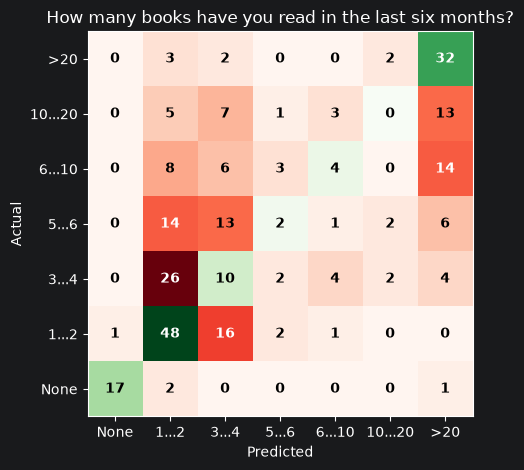

In [147]:
# TODO Assess the factors most responsible for determining a person's reading habits (PCA)
# TODO Determine the feasibility of a model for recommending books to a person according to their answers

def main():
    raw_data: pl.DataFrame = pl.read_csv("Lugeja25.tab", has_header=True, separator="\t")
    typed_data: tp.DataFrame[Answer] = tp.DataFrame(Answer, values=raw_data)
    # print(typed_data.head(1))
    # predict_habits(typed_data)
    # visualize_readership(data=q11_nulls_to_zero_data)

    #is_reader_data = typed_data.transform(AnswerParts1_6)
    #find_best_params_for_catboost(is_reader_data)
    #is_reader_predictions: tp.DataFrame[PredictedAndActualQ1] = predict_is_reader_parts_1_6(is_reader_data)
    #visualize_is_reader_predictions(is_reader_predictions)

    habits = predict_habits(typed_data)
    visualize_predict_habits(habits)

if __name__ == "__main__":
    main()